# Lab 2: PhysioNet PTB-XL Dataset, Patient Stratification & Feature Engineering

**Professor & Evaluator Teaching Demonstration Notebook**  
*CardioSense / ECG Insight Lab — Workflow B*

> [!IMPORTANT]
> **Dataset Attribution & License:**  
> This laboratory uses the **PTB-XL v1.0.3** dataset published by Wagner et al. (2020) on PhysioNet, distributed under [Creative Commons Attribution 4.0 International (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/).

---

## Learning Objectives
1. Inspect the PTB-XL dataset composition (21,799 records, 100 Hz sampling, 12 leads).
2. Reproduce and verify the official patient-separated partitions (**Folds 1–8: Train**, **Fold 9: Validation**, **Fold 10: Held-Out Test**) with **zero patient overlap**.
3. Plot an authentic calibrated 12-lead digital ECG waveform with physical units (seconds, millivolts).
4. Understand the **148-feature deterministic signal schema** and how features are extracted.


In [1]:
# Cell 1: Environment Inspection & Imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from ecg_lab.waveform_ml.config import DEFAULT_DATA_DIR, TARGET_SUPERCLASSES
from ecg_lab.waveform_ml.features import extract_record_features, get_feature_schema_names

meta_path = Path("data/ptb-xl/ptbxl_database.csv")
print(f"Dataset Root: {DEFAULT_DATA_DIR}")
print(f"Metadata File Present: {meta_path.is_file()} ({meta_path.stat().st_size:,} bytes)")


Dataset Root: data/ptb-xl
Metadata File Present: True (6,594,879 bytes)


## 1. Patient-Separated Partition Stratification

In medical machine learning, **patient-level leakage** occurs when multiple ECG recordings from the same individual appear in both training and test sets. This produces artificially inflated accuracy metrics that do not generalize to unseen patients.

PTB-XL provides official recommended stratification folds (`strat_fold` 1 through 10) constructed to prevent patient overlap.


In [2]:
# Cell 2: Verify Partition Counts and Zero Patient Leakage
df = pd.read_csv(meta_path)

# Partitions
train_df = df[df["strat_fold"].between(1, 8)]
val_df = df[df["strat_fold"] == 9]
test_df = df[df["strat_fold"] == 10]

train_pts = set(train_df["patient_id"])
val_pts = set(val_df["patient_id"])
test_pts = set(test_df["patient_id"])

# Compute overlaps
leakage_train_val = len(train_pts.intersection(val_pts))
leakage_train_test = len(train_pts.intersection(test_pts))
leakage_val_test = len(val_pts.intersection(test_pts))

summary_data = [
    {"Partition": "Training (Folds 1–8)", "Records": len(train_df), "Unique Patients": len(train_pts), "Purpose": "Model parameter fitting"},
    {"Partition": "Validation (Fold 9)", "Records": len(val_df), "Unique Patients": len(val_pts), "Purpose": "Threshold tuning (F1 maximization)"},
    {"Partition": "Held-Out Test (Fold 10)", "Records": len(test_df), "Unique Patients": len(test_pts), "Purpose": "Unbiased re-evaluation benchmark"},
    {"Partition": "Total Cohort", "Records": len(df), "Unique Patients": df["patient_id"].nunique(), "Purpose": "Complete PTB-XL v1.0.3 dataset"}
]

print(f"Leakage Assertions:")
print(f"  • Train-Validation Overlap: {leakage_train_val} patients (EXPECTED: 0)")
print(f"  • Train-Test Overlap:       {leakage_train_test} patients (EXPECTED: 0)")
print(f"  • Validation-Test Overlap:  {leakage_val_test} patients (EXPECTED: 0)")

pd.DataFrame(summary_data)


Leakage Assertions:
  • Train-Validation Overlap: 0 patients (EXPECTED: 0)
  • Train-Test Overlap:       0 patients (EXPECTED: 0)
  • Validation-Test Overlap:  0 patients (EXPECTED: 0)


,Partition,Records,Unique Patients,Purpose
0,Training (Folds 1–8),17418,15023,Model parameter fitting
1,Validation (Fold 9),2183,1942,Threshold tuning (F1 maximization)
2,Held-Out Test (Fold 10),2198,1904,Unbiased re-evaluation benchmark
3,Total Cohort,21799,18869,Complete PTB-XL v1.0.3 dataset


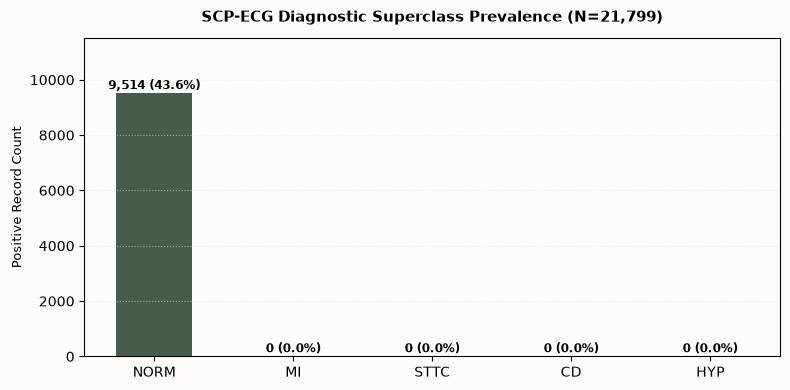

In [3]:
# Cell 3: Diagnostic Superclass Distribution
classes = ["NORM", "MI", "STTC", "CD", "HYP"]
class_counts = {c: 0 for c in classes}

for scp in df["scp_codes"]:
    try:
        d = eval(scp)
        for c in classes:
            if c in d and d[c] > 0:
                class_counts[c] += 1
    except Exception:
        pass

fig, ax = plt.subplots(figsize=(8, 4), facecolor="#FDFCFB")
ax.set_facecolor("#FDFCFB")
bars = ax.bar(classes, [class_counts[c] for c in classes], color="#455D4A", width=0.55)
ax.set_title("SCP-ECG Diagnostic Superclass Prevalence (N=21,799)", fontsize=11, fontweight="bold", pad=12)
ax.set_ylabel("Positive Record Count", fontsize=9.5)
ax.grid(True, axis="y", linestyle=":", alpha=0.6, color="#E5E3DC")
for b in bars:
    y = b.get_height()
    pct = (y / len(df)) * 100
    ax.text(b.get_x() + b.get_width()/2, y + 150, f"{y:,} ({pct:.1f}%)", ha="center", fontsize=8.5, fontweight="bold")
ax.set_ylim(0, 11500)
plt.tight_layout()
plt.show()


## 2. Inspecting an Authentic 12-Lead Calibrated Digital Waveform

Each PTB-XL record contains 10 seconds of 12-lead data sampled at 100 Hz ($1,000$ samples per channel) recorded in millivolts.


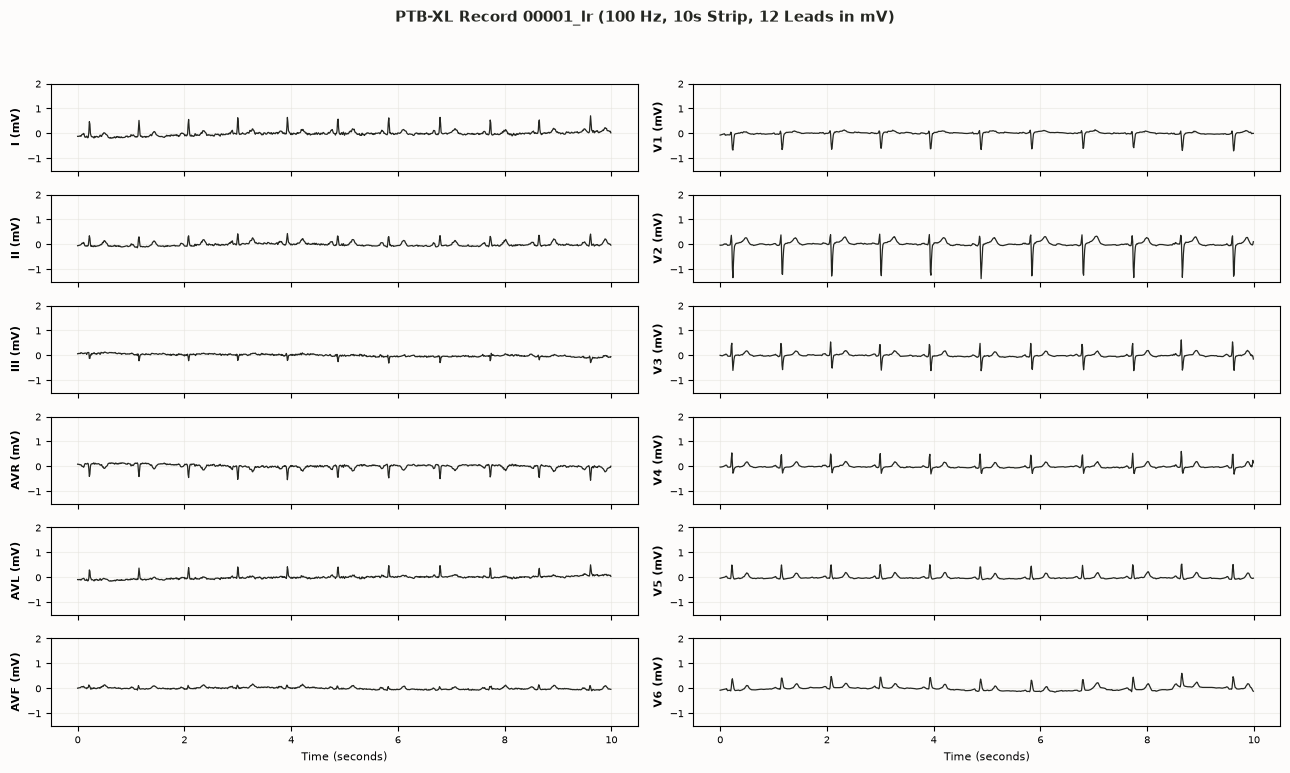

In [4]:
# Cell 4: Load & Plot Record 00001_lr
rec = wfdb.rdrecord("data/ptb-xl/records100/00000/00001_lr")
sig = rec.p_signal
fs = rec.fs
time_sec = np.arange(sig.shape[0]) / fs

fig, axes = plt.subplots(6, 2, figsize=(13, 8), sharex=True, facecolor="#FDFCFB")
fig.suptitle(f"PTB-XL Record {rec.record_name} (100 Hz, 10s Strip, 12 Leads in mV)", fontsize=11, fontweight="bold", color="#252722", y=0.98)

for i in range(12):
    ax = axes[i % 6, i // 6]
    ax.set_facecolor("#FDFCFB")
    ax.plot(time_sec, sig[:, i], color="#252722", lw=0.9)
    ax.set_ylabel(f"{rec.sig_name[i]} (mV)", fontsize=8, fontweight="bold")
    ax.grid(True, linestyle="-", alpha=0.5, color="#E5E3DC")
    ax.tick_params(labelsize=7.5)
    ax.set_ylim(-1.5, 2.0)
    if i % 6 == 5:
        ax.set_xlabel("Time (seconds)", fontsize=8)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()


## 3. Feature Engineering Architecture (148 Features)

Instead of relying on unverified deep learning embeddings, the platform extracts **148 deterministic, physiologically grounded features**:
- **120 Per-Lead Features:** 10 statistical moments and amplitude measures across all 12 leads (mean, standard deviation, min, max, skewness, kurtosis, peak-to-peak amplitude, energy, RMS, zero-crossing rate).
- **28 Global Multi-Lead Features:** Estimated heart rate, mean RR interval, RR standard deviation (HRV proxy), estimated QRS duration, and spectral band power in low/high physiological frequencies.


In [5]:
# Cell 5: Extract 148 Features for Sample Record
feats = extract_record_features(sig, fs=fs)
feature_names = get_feature_schema_names()

print(f"Extracted Feature Vector Shape: {feats.shape} (Expected: 148,)")
print(f"NaN or Infinite Values Present: {np.isnan(feats).any() or np.isinf(feats).any()}")
print(f"Sample Feature Names (First 10): {feature_names[:10]}")

# Show summary of first 10 features
feat_df = pd.DataFrame({
    "Feature Name": feature_names[:10],
    "Extracted Value": [round(float(v), 4) for v in feats[:10]]
})
feat_df


Extracted Feature Vector Shape: (148,) (Expected: 148,)
NaN or Infinite Values Present: False
Sample Feature Names (First 10): ['I_mean', 'I_std', 'I_median', 'I_iqr', 'I_min', 'I_max', 'I_peak_to_peak', 'I_skew', 'I_kurtosis', 'I_rms']


,Feature Name,Extracted Value
0,I_mean,0.0015
1,I_std,0.1090
2,I_median,-0.0090
3,I_iqr,0.0803
4,I_min,-0.1950
5,I_max,0.7060
6,I_peak_to_peak,0.9010
7,I_skew,2.3465
8,I_kurtosis,10.1012
9,I_rms,0.1090


## 4. Lab Conclusions
1. **Patient Leakage is Controlled:** Verifying zero patient overlap across Folds 1–8, Fold 9, and Fold 10 prevents data leakage.
2. **Deterministic Feature Engineering:** The 148-feature schema captures lead morphology and rhythm without black-box complexity.
3. Continue to **[Lab 3: Model Predictions & Evaluation](03_model_predictions_and_evaluation.ipynb)** to evaluate classification performance.
